In [38]:
import sys
import time
from pathlib import Path

PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import torch
import matplotlib.pyplot as plt
import matplotlib.patches as patches

from torchmetrics.detection.mean_ap import MeanAveragePrecision
from ultralytics import YOLO

from datasets.coin_detection_dataset import CoinDetectionDataset
from models.custom_detector import CustomDetector

device = "mps"

CLASS_NAMES = ["1 gr", "2 gr", "5 gr", "10 gr", "20 gr", "50 gr", "1 zl", "2 zl", "5 zl"]

In [ ]:
YOLO_DIR = PROJECT_ROOT / "checkpoints/yolo_coin"
YOLO_CHECKPOINT = YOLO_DIR / "weights/best.pt"

yolo = YOLO("yolo26n.pt")
yolo.train(
    data=str(PROJECT_ROOT / "data/processed/data.yaml"),
    epochs=50,
    imgsz=640,
    batch=16,
    device=device,
    project=str(PROJECT_ROOT / "checkpoints"),
    name="yolo_coin",
    exist_ok=True)

yolo = YOLO(str(YOLO_CHECKPOINT))

Ultralytics 8.4.202 🚀 Python-3.15.0 torch-2.15.0 MPS (Apple M3)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/Users/patryknisgorski/_aii/data/processed/data.yaml, degrees=0.0, deterministic=True, device=mps, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo_coin, nbs=64, nms=None, opset=None, optimize=False

/Users/patryknisgorski/_aii/.venv/lib/python3.15/site-packages/torch/autograd/graph.py:1113: UserWarning: index_put_with_accumulate_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/Context.cpp:224.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


       1/50      8.46G     0.6105      4.479     0.0026         74        640: 100% ━━━━━━━━━━━━ 4/4 1.2s/it 4.6s1.3ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 1.9it/s 0.5s
                   all         18        177      0.046       0.56     0.0671     0.0569

      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size


/Users/patryknisgorski/_aii/.venv/lib/python3.15/site-packages/torch/autograd/graph.py:1113: UserWarning: index_put_with_accumulate_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/Context.cpp:224.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


       2/50      9.43G     0.6698      4.277   0.002798         69        640: 100% ━━━━━━━━━━━━ 4/4 1.1it/s 3.7s1.3s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 1.9it/s 0.5s
                   all         18        177     0.0495      0.835      0.108     0.0879

      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size


/Users/patryknisgorski/_aii/.venv/lib/python3.15/site-packages/torch/autograd/graph.py:1113: UserWarning: index_put_with_accumulate_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/Context.cpp:224.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


... (91 outputs left out)

/Users/patryknisgorski/_aii/.venv/lib/python3.15/site-packages/torch/autograd/graph.py:1113: UserWarning: index_put_with_accumulate_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/Context.cpp:224.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


      49/50      9.43G     0.5354      1.449   0.002577         45        640: 100% ━━━━━━━━━━━━ 4/4 1.4s/it 5.7s1.8ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 2.0it/s 0.5s
                   all         18        177      0.736      0.865      0.854      0.781

      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
      50/50      8.35G     0.4911      1.377    0.00245        181        640: 0% ──────────── 0/4  1.0s

/Users/patryknisgorski/_aii/.venv/lib/python3.15/site-packages/torch/autograd/graph.py:1113: UserWarning: index_put_with_accumulate_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/Context.cpp:224.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


      50/50       8.4G     0.4852      1.391   0.002449         44        640: 100% ━━━━━━━━━━━━ 4/4 1.4s/it 5.4s1.6ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 2.0it/s 0.5s
                   all         18        177      0.715      0.883      0.853       0.78

50 epochs completed in 0.076 hours.
Optimizer stripped from /Users/patryknisgorski/_aii/checkpoints/yolo_coin/weights/last.pt, 5.4MB
Optimizer stripped from /Users/patryknisgorski/_aii/checkpoints/yolo_coin/weights/best.pt, 5.4MB

Validating /Users/patryknisgorski/_aii/checkpoints/yolo_coin/weights/best.pt...
Ultralytics 8.4.202 🚀 Python-3.15.0 torch-2.15.0 MPS (Apple M3)
YOLO26n summary (fused): 121 layers, 2,391,679 parameters, 0 gradients, 5.4 GFLOPs
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 2.8it/s 0.4s
                   all         18        177      0.732      0.852      0.859      

In [40]:
custom_detector = CustomDetector(
    background_checkpoint=PROJECT_ROOT / "checkpoints/background_best.pth",
    regressor_checkpoint=PROJECT_ROOT / "checkpoints/regressor_best.pth",
    classifier_checkpoint=PROJECT_ROOT / "checkpoints/classifier_best.pth",
    device=device,
)

val_ds = CoinDetectionDataset(PROJECT_ROOT / "data/raw/val.pkl")

In [ ]:
def empty_prediction():
    return {
        "boxes": torch.empty((0, 4), dtype=torch.float32),
        "labels": torch.empty((0,), dtype=torch.long),
        "scores": torch.empty((0,), dtype=torch.float32)}


def predict_custom(image):
    detections = custom_detector.predict(image)

    if not detections:
        return empty_prediction()

    return {
        "boxes": torch.tensor([d[:4] for d in detections], dtype=torch.float32),
        "labels": torch.tensor([d[4] for d in detections], dtype=torch.long),
        "scores": torch.tensor([d[5] for d in detections], dtype=torch.float32)
    }


def predict_yolo(image, confidence=0.25):
    image_array = (image.permute(1, 2, 0).numpy() * 255).astype(np.uint8)[:, :, ::-1]
    result = yolo.predict(image_array, conf=confidence, device=device, verbose=False)[0]

    if result.boxes is None or len(result.boxes) == 0:
        return empty_prediction()

    return {
        "boxes": result.boxes.xyxy.cpu().float(),
        "labels": result.boxes.cls.cpu().long(),
        "scores": result.boxes.conf.cpu().float(),
    }


def draw_predictions(ax, image, prediction, title):
    ax.imshow(image.permute(1, 2, 0))

    for box, label, score in zip(prediction["boxes"], prediction["labels"], prediction["scores"]):
        x1, y1, x2, y2 = box.tolist()
        rectangle = patches.Rectangle((x1, y1), x2 - x1, y2 - y1, linewidth=2, edgecolor="lime", facecolor="none")
        ax.add_patch(rectangle)
        ax.text(x1, y1, f"{CLASS_NAMES[int(label)]} {float(score):.2f}", color="yellow", backgroundcolor="black")

    ax.set_title(title)
    ax.axis("off")

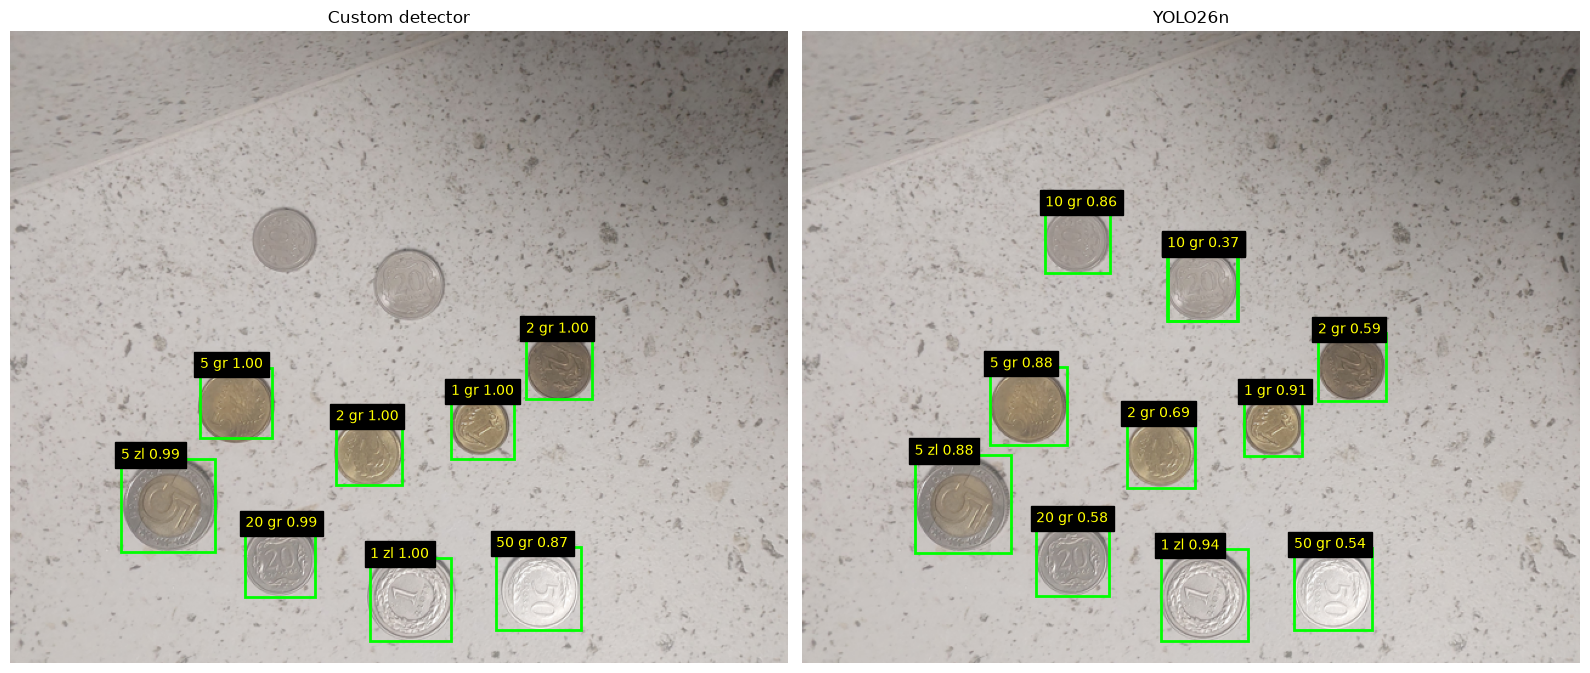

In [42]:
sample = val_ds[0]
image = sample["image"]

custom_prediction = predict_custom(image)
yolo_prediction = predict_yolo(image)

fig, axes = plt.subplots(1, 2, figsize=(16, 8))
draw_predictions(axes[0], image, custom_prediction, "Custom detector")
draw_predictions(axes[1], image, yolo_prediction, "YOLO26n")
plt.tight_layout()
plt.show()

In [ ]:
custom_metric = MeanAveragePrecision(box_format="xyxy", iou_type="bbox")
yolo_metric = MeanAveragePrecision(box_format="xyxy", iou_type="bbox")
custom_time = 0.0
yolo_time = 0.0

for sample in val_ds:
    image = sample["image"]
    target = [{"boxes": sample["boxes"], "labels": sample["labels"]}]

    torch.mps.synchronize()
    start = time.perf_counter()
    custom_prediction = predict_custom(image)
    
    torch.mps.synchronize()
    custom_time += time.perf_counter() - start

    torch.mps.synchronize()
    start = time.perf_counter()
    yolo_prediction = predict_yolo(image, confidence=0.001)

    torch.mps.synchronize()
    yolo_time += time.perf_counter() - start

    custom_metric.update([custom_prediction], target)
    yolo_metric.update([yolo_prediction], target)

custom_results = custom_metric.compute()
yolo_results = yolo_metric.compute()

comparison = {
    "Custom detector": {
        "mAP@0.5:0.95": custom_results["map"].item(),
        "mAP@0.5": custom_results["map_50"].item(),
        "ms/image": custom_time / len(val_ds) * 1000,
    },
    "YOLO26n": {
        "mAP@0.5:0.95": yolo_results["map"].item(),
        "mAP@0.5": yolo_results["map_50"].item(),
        "ms/image": yolo_time / len(val_ds) * 1000,
    },
}

for model_name, values in comparison.items():
    print(model_name)
    for metric_name, value in values.items():
        print(f"  {metric_name}: {value:.4f}")

/Users/patryknisgorski/_aii/.venv/lib/python3.15/site-packages/torchmetrics/utilities/prints.py:43: UserWarning: Encountered more than 100 detections in a single image. This means that certain detections with the lowest scores will be ignored, that may have an undesirable impact on performance. Please consider adjusting the `max_detection_threshold` to suit your use case. To disable this warning, set attribute class `warn_on_many_detections=False`, after initializing the metric.
  warnings.warn(*args, **kwargs)


Custom detector
  mAP@0.5:0.95: 0.5752
  mAP@0.5: 0.7810
  ms/image: 925.3445
YOLO26n
  mAP@0.5:0.95: 0.7758
  mAP@0.5: 0.8506
  ms/image: 31.0047


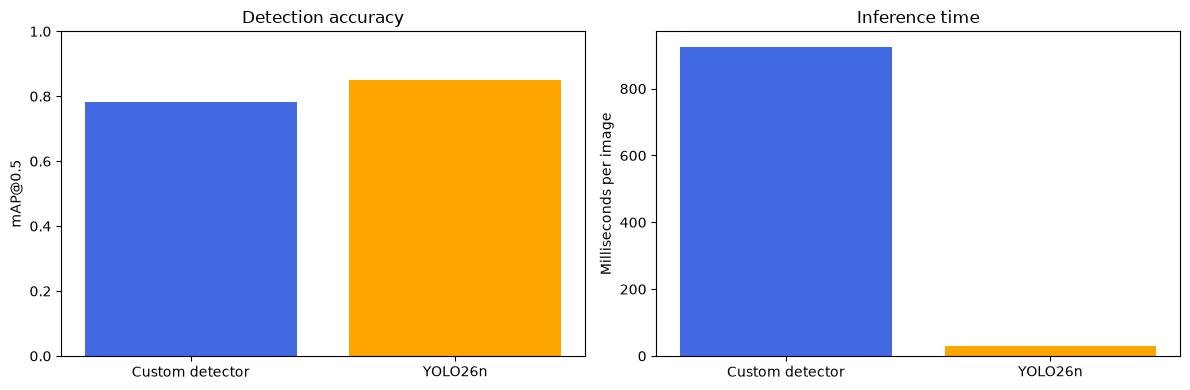

In [44]:
model_names = list(comparison.keys())
map_values = [comparison[name]["mAP@0.5"] for name in model_names]
speed_values = [comparison[name]["ms/image"] for name in model_names]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(model_names, map_values, color=["royalblue", "orange"])
axes[0].set_title("Detection accuracy")
axes[0].set_ylabel("mAP@0.5")
axes[0].set_ylim(0, 1)

axes[1].bar(model_names, speed_values, color=["royalblue", "orange"])
axes[1].set_title("Inference time")
axes[1].set_ylabel("Milliseconds per image")

plt.tight_layout()
plt.show()